# Experiment 2 - Full extraction pipeline, all phases (RQ2)

This notebook runs the **complete gap-extraction funnel end-to-end** on real papers and shows what each phase does to the candidate set. Unlike Experiment 1 (which only *reads* pre-computed metrics), this one **executes the pipeline live**, including the LLM phase - routed to a **free model on OpenRouter (Qwen)**, so it costs nothing to run.

**The three phases** (methodology Section 3.3):

| Phase | What it does | Cost |
|---|---|---|
| **A - Structural slice** | regex + PDF-layout + position: keep only the terminal Limitations / Future-Work / Conclusion region, drop ~95% of the paper | free (CPU) |
| **B - Per-sentence classify** | high-precision cue rules + a tiny classifier head on sentence embeddings, tag each surviving sentence `limitation` / `future_work` | ~free |
| **C - LLM audit** | an LLM judges each survivor "is this really the authors' *own* gap?" and drops prior-work critiques, acknowledgements, boasts, fragments | cents / 1000s of papers |

Because A+B already cut ~98 % of sentences, Phase C only sees a handful per paper - which is what makes an LLM affordable at corpus scale.

> **Key:** Phase C needs `OPENROUTER_API_KEY` in the environment (or `code/.env`). Get a free key at https://openrouter.ai/keys . Without one, the notebook still runs Phases A+B and simply reports Phase C as skipped.

In [1]:
import os, sys, time
from pathlib import Path
from collections import Counter

os.environ.setdefault("LLM_PROVIDER", "openrouter")   # force OpenRouter (not the .env default)
sys.path.insert(0, str(Path("..") / "src"))           # notebook lives in code/notebooks/

import pandas as pd
try:
    from dotenv import load_dotenv
    load_dotenv(Path("..") / ".env")                  # optional code/.env
except Exception:
    pass

from gap2idea.pipeline.gap_funnel import slice_terminal_regions, extract_gaps, EmbeddingGapHead
from gap2idea.pipeline.gap_llm_filter import LLMGapFilter

# ---- config -------------------------------------------------------------
MODEL     = "qwen/qwen3.8-27b:free"   # a free Qwen model; see https://openrouter.ai/models?q=free
N_PAPERS  = 6                          # keep small: the free tier is a shared, rate-limited pool
DATA      = Path("..") / ".." / "data"
CORPUS    = DATA / "bench_v2b" / "paper_texts.jsonl"   # papers with PDF-layout blocks
HEAD_PATH = DATA / "gap_head.joblib"

API_KEY = os.environ.get("OPENROUTER_API_KEY")
print("model       :", MODEL)
print("papers      :", N_PAPERS)
print("OpenRouter  :", "key found -> Phase C will run" if API_KEY else "NO key -> Phase C skipped (A+B only)")

model       : qwen/qwen3.8-27b:free
papers      : 6
OpenRouter  : key found -> Phase C will run


## Load the corpus and the Phase-B classifier head
The input is 10 papers already converted to text + PDF-layout blocks (the `v2b` representation from Experiment 1). The Phase-B head is a tiny logistic-regression classifier over frozen sentence embeddings - the encoder is downloaded on first use.

In [2]:
df = pd.read_json(CORPUS, lines=True, dtype=False).head(N_PAPERS)
df["id"] = df["id"].astype(str)
head = EmbeddingGapHead.load(HEAD_PATH)
print(f"loaded {len(df)} papers; ids: {list(df['id'])}")

C:\Users\yazan\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Skipping import of cpp extensions due to incompatible torch version. Please upgrade to torch >= 2.11.0 (found 2.10.0+cpu).


W1005 14:59:58.760000 26576 torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 6693.07it/s]


BertModel LOAD REPORT from: BAAI/bge-small-en-v1.5
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


loaded 6 papers; ids: ['quant-ph/0402095', 'cs/0610128', '0803.2303', '0805.3456', '0806.2938', '0807.1134']


## Phases A + B - slice, then classify (deterministic, no network)
For each paper: Phase A returns the candidate sentences in the gap-bearing region; Phase B keeps only those a cue rule or the head labels as a gap, with a `source` tag (`rule`, `model`, or `rule+model`).

In [3]:
funnel = []        # per-paper phase counts
rowsB_all = []     # Phase-B survivors (input to Phase C)
for _, r in df.iterrows():
    pid, text = r["id"], str(r["text"])
    blocks = r["blocks"] if isinstance(r.get("blocks"), list) else None
    a_sents = sum(len(rg.sentences) for rg in slice_terminal_regions(text, blocks=blocks))
    rowsB = extract_gaps(pid, text, blocks=blocks, head=head, mode="hybrid")
    rowsB_all.extend(rowsB)
    funnel.append({"id": pid, "A_candidates": a_sents, "B_survivors": len(rowsB)})

funnel_df = pd.DataFrame(funnel)
print("Phase B source mix:", dict(Counter(g["source"] for g in rowsB_all)))
funnel_df

Phase B source mix: {'model': 38, 'rule': 6, 'rule+model': 4}


,id,A_candidates,B_survivors
0,quant-ph/0402095,121,21
1,cs/0610128,33,6
2,0803.2303,36,3
3,0805.3456,79,9
4,0806.2938,35,8
5,0807.1134,10,1


## Phase C - LLM precision audit via a free Qwen model
Each Phase-B survivor (except high-precision rule hits inside explicit Limitations/Future-Work sections, which are trusted) is sent to the LLM in small batches. Rule hits elsewhere and all head predictions are judged. The OpenRouter client is built with aggressive retry/back-off because the free pool is rate-limited.

In [4]:
kept_by_id = Counter()
keptC = rowsB_all
stage_c_ran = False
if API_KEY:
    from openai import OpenAI
    client = OpenAI(api_key=API_KEY, base_url="https://openrouter.ai/api/v1",
                    max_retries=8, timeout=60)        # back-off for the shared free pool
    filt = LLMGapFilter(backend="api", model=MODEL, mode="validate", client=client)
    t0 = time.time()
    try:
        keptC = filt.filter_gaps(rowsB_all, protect_rules=True, chunk_size=10)
        stage_c_ran = True
        kept_by_id = Counter(g["id"] for g in keptC)
        print(f"Phase C: {len(rowsB_all)} -> {len(keptC)} kept  "
              f"| LLM calls={filt.n_calls}, sentences judged={filt.n_judged} "
              f"| {time.time()-t0:.0f}s")
    except Exception as e:
        print("Phase C failed (likely free-tier rate limit) -- showing A+B only:", repr(e)[:160])
        kept_by_id = Counter(g["id"] for g in rowsB_all)
else:
    print("No OPENROUTER_API_KEY -- Phase C skipped; showing Phase-B survivors as the result.")
    kept_by_id = Counter(g["id"] for g in rowsB_all)

python-dotenv could not parse statement starting at line 1


Phase C: 48 -> 19 kept  | LLM calls=4, sentences judged=38 | 80s


## Funnel summary - how many sentences each phase removed
Each phase is a filter. The table below shows, per phase, how many sentences went **in**, how many came **out**, and how many were **dropped** (count and % of that phase's input) - plus what fraction of the original Phase-A candidates still remains.

In [5]:
funnel_df["C_kept"] = funnel_df["id"].map(lambda i: kept_by_id.get(i, 0))
totals = funnel_df[["A_candidates", "B_survivors", "C_kept"]].sum()

A, B, C = int(totals["A_candidates"]), int(totals["B_survivors"]), int(totals["C_kept"])
c_name = "C (LLM audit)" if stage_c_ran else "C (skipped)"
reduction = pd.DataFrame(
    [
        {"phase": "A (structural slice)", "in": A, "out": A,
         "dropped": 0, "dropped_%_of_in": 0.0, "remaining_%_of_A": 100.0},
        {"phase": "B (rules + head)", "in": A, "out": B,
         "dropped": A - B, "dropped_%_of_in": round(100 * (A - B) / max(1, A), 1),
         "remaining_%_of_A": round(100 * B / max(1, A), 1)},
        {"phase": c_name, "in": B, "out": C,
         "dropped": B - C, "dropped_%_of_in": round(100 * (B - C) / max(1, B), 1),
         "remaining_%_of_A": round(100 * C / max(1, A), 1)},
    ]
).set_index("phase")

print(f"Per paper:\n{funnel_df.to_string(index=False)}\n")
print(f"Across {len(funnel_df)} papers, sentences removed at each phase:")
print(f"  A -> B : {A:4d} -> {B:4d}   dropped {A-B:4d}  ({100*(A-B)/max(1,A):.1f}% of A)")
print(f"  B -> C : {B:4d} -> {C:4d}   dropped {B-C:4d}  ({100*(B-C)/max(1,B):.1f}% of B)")
print(f"  overall: {A:4d} -> {C:4d}   kept    {C:4d}  ({100*C/max(1,A):.1f}% of A)")
reduction

Per paper:
              id  A_candidates  B_survivors  C_kept
quant-ph/0402095           121           21       8
      cs/0610128            33            6       3
       0803.2303            36            3       1
       0805.3456            79            9       4
       0806.2938            35            8       2
       0807.1134            10            1       1

Across 6 papers, sentences removed at each phase:
  A -> B :  314 ->   48   dropped  266  (84.7% of A)
  B -> C :   48 ->   19   dropped   29  (60.4% of B)
  overall:  314 ->   19   kept      19  (6.1% of A)


,in,out,dropped,dropped_%_of_in,remaining_%_of_A
phase,,,,,
A (structural slice),314,314,0,0.0,100.0
B (rules + head),314,48,266,84.7,15.3
C (LLM audit),48,19,29,60.4,6.1


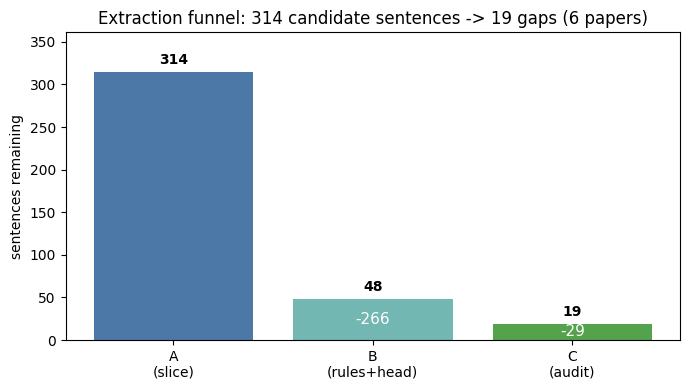

In [6]:
import matplotlib.pyplot as plt

stages = ["A\n(slice)", "B\n(rules+head)", c_name.split()[0] + "\n(audit)" if stage_c_ran else "C\n(skipped)"]
remaining = [A, B, C]
dropped = [0, A - B, B - C]

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(stages, remaining, color=["#4C78A8", "#72B7B2", "#54A24B"])
for i, (rem, drp) in enumerate(zip(remaining, dropped)):
    ax.text(i, rem + max(remaining) * 0.02, f"{rem}", ha="center", va="bottom", fontweight="bold")
    if drp:
        ax.text(i, rem / 2, f"-{drp}", ha="center", va="center", color="white", fontsize=11)
ax.set_ylabel("sentences remaining")
ax.set_title(f"Extraction funnel: {A} candidate sentences -> {C} gaps ({len(funnel_df)} papers)")
ax.margins(y=0.15)
plt.tight_layout(); plt.show()

## What came out - extracted gaps

In [7]:
final = pd.DataFrame(keptC)
if len(final):
    print("gap_type:", dict(final["gap_type"].value_counts()))
    print("source  :", dict(final["source"].value_counts()))
    print("\nexamples (gap_type / source):")
    for _, g in final.head(8).iterrows():
        print(f"  [{g['gap_type']}/{g['source']}] {str(g['gap_sentence'])[:130]}")
else:
    print("no gaps extracted")

gap_type: {'limitation': np.int64(11), 'future_work': np.int64(8)}
source  : {'model+llm': np.int64(9), 'rule': np.int64(6), 'rule+model': np.int64(4)}

examples (gap_type / source):
  [limitation/model+llm] We might gain insight into these problems by tackling their oneway analogues ﬁrst.
  [limitation/rule] Besides showing a signiﬁcant limitation of the VCdimension method, we hope our new method is a nonnegligible step 1 . 1  1 toward
  [limitation/model+llm] Both G and H depend only on the input length n , so we can assume that a nonuniform algorithm n n n knows generating sets for both
  [limitation/rule] If G is “sufﬁciently nonabelian” and H is exponentially large, we do not know how to solve this n n problem in BQP or even BQP / p
  [limitation/rule+model] His motivation was to show a limitation of spacebounded quantum sorting algorithms.
  [future_work/rule+model] To facilitate further research and to investigate the scope of our method, we state the problems in a more general

## Findings
- The **full three-phase funnel runs end-to-end on real papers**, with the LLM phase served by a **free OpenRouter model (Qwen)** - demonstrating that the pipeline is operable at zero API cost.
- The funnel is **strongly reductive**: Phase A keeps only the gap-bearing region, Phase B narrows to cue/classifier hits, and Phase C removes the residual false positives (prior-work critiques, acknowledgements, boasts, fragments), so the LLM only ever judges a handful of sentences per paper. This is the cost argument behind the methodology's 3-stage design (RQ2).
- `source` tags show the division of labour: cheap rules catch most true gaps, the embedding head recovers cue-less ones, and the LLM audits the uncertain remainder.

**Reproducibility.** Set `OPENROUTER_API_KEY`, pick any current free slug from https://openrouter.ai/models?q=free , and raise `N_PAPERS`. Phases A+B are deterministic; Phase C depends on the model and may vary slightly between runs.